# 07. Avaliação no Teste e Generalização

**DCT1401 — Inteligência Artificial (UFRN, 2026.2)**
**Aluna:** Mariana dos Santos Batista Medeiros (Matrícula: 20230083988)

**Atividade 03 — Redes Neurais Artificiais com PyTorch: Classificação e Regressão**

Este notebook avalia os modelos finais de regressão e de classificação **carregados dos arquivos `.pt`** salvos no Notebook 06, ao lado dos modelos da configuração de referência, e analisa a generalização: gap entre treino, validação e teste, curvas de aprendizado, diagnóstico de subajuste e sobreajuste nas configurações extremas do estudo de hiperparâmetros e validação cruzada.

**Uso do conjunto de teste.** Os modelos, as sementes e os limiares de decisão foram congelados antes de qualquer contato com o teste, e a impressão digital dos pesos foi registrada nesse momento. Este notebook confere essas impressões digitais e reutiliza as previsões do teste gravadas pelos modelos carregados, sem nova inferência sobre o teste nos resultados principais. Nenhum resultado deste notebook é usado para escolher ou alterar modelos, sementes ou limiares.

O notebook tem duas partes:

- **Resultados principais (Seções 1 a 3):** métricas dos modelos salvos no treino, na validação e no teste, curvas ROC e Precision–Recall, resíduos, gap e diagnóstico de generalização.
- **Análises complementares (Seção 4):** variação entre cinco sementes no teste e validação cruzada *K-fold*. Elas descrevem a robustez da configuração final; não constituem novas avaliações independentes nem critérios de escolha.

Nas tabelas, **treino** corresponde ao subconjunto de ajuste (12.800 registros), o único usado para atualizar os pesos.

**Configuração do ambiente — Google Colab**

Esta etapa conecta o Google Colab ao Google Drive e configura os caminhos necessários para acessar o dataset original, os módulos Python do projeto e os arquivos produzidos pelos Notebooks 05 e 06.

In [3]:
from google.colab import drive
from pathlib import Path
import importlib
import os
import sys

drive.mount("/content/drive")
PROJETO = Path("/content/drive/MyDrive/projeto-cardiovascular-ia-03")

ARQUIVO_RAW = PROJETO / "data/raw/cardiovascular_disease_prediction.csv"
assert ARQUIVO_RAW.is_file(), f"Dataset original não encontrado: {ARQUIVO_RAW}"
for modulo in ["__init__.py", "pipeline_data.py", "models.py", "train.py", "metrics.py", "inference.py"]:
    assert (PROJETO / "src" / modulo).is_file(), f"Módulo ausente em src/: {modulo}"
for arquivo in ["logs/hiperparametros.csv", "logs/configuracao_final.json", "logs/congelamento_modelos.json",
                "logs/previsoes_teste.csv", "models/modelo_regressao.pt", "models/modelo_classificacao.pt",
                "models/referencia/baseline_regressao.pt", "models/referencia/baseline_classificacao.pt"]:
    assert (PROJETO / arquivo).is_file(), f"Arquivo dos Notebooks 05/06 ausente: {arquivo}"

os.chdir(PROJETO / "notebooks")
if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))

import src.pipeline_data as pipeline_data
import src.models as modelos_mlp
import src.metrics as metricas
import src.train as treino
import src.inference as inferencia
for modulo in (pipeline_data, modelos_mlp, metricas, treino, inferencia):
    importlib.reload(modulo)

pasta_modelos = PROJETO / "models"
pasta_logs = PROJETO / "logs"
pasta_tabelas = PROJETO / "reports" / "tables"
pasta_figuras = PROJETO / "reports" / "figures"
for pasta in (pasta_tabelas, pasta_figuras):
    pasta.mkdir(parents=True, exist_ok=True)
print("Projeto localizado em:", PROJETO)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projeto localizado em: /content/drive/MyDrive/projeto-cardiovascular-ia-03


In [4]:
import hashlib
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from scipy import stats
from scipy.special import expit
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, roc_curve

DEVICE = "cpu"
ambiente = {
    "Modelo da CPU": treino.modelo_cpu(),
    "Threads do PyTorch": torch.get_num_threads(),
    "Python": platform.python_version(),
    "PyTorch": torch.__version__,
    "scikit-learn": sklearn.__version__,
    "GPU disponível": torch.cuda.is_available(),
    "Dispositivo utilizado": DEVICE,
}
display(pd.Series(ambiente, name="Valor").to_frame())

,Valor
Modelo da CPU,Intel(R) Xeon(R) CPU @ 2.20GHz
Threads do PyTorch,1
Python,3.13.18
PyTorch,2.14.1+cpu
scikit-learn,1.6.1
GPU disponível,False
Dispositivo utilizado,cpu


## 1. Verificação dos modelos congelados e das previsões do teste

Antes de qualquer métrica, confere-se que os arquivos usados aqui são exatamente os congelados no Notebook 06:

- a **impressão digital dos pesos** (SHA-256 dos tensores do `state_dict`) de cada modelo carregado é igual à registrada antes do contato com o teste;
- os arquivos `.pt` e o arquivo de previsões do teste não foram alterados (SHA-256 dos arquivos);
- a semente e o limiar guardados em cada checkpoint são os registrados no congelamento;
- as previsões do teste estão associadas aos mesmos registros e alvos da divisão reproduzida a partir do CSV original.

As previsões são lidas com `float_precision="round_trip"`, que recupera exatamente os valores gravados.

In [5]:
def impressao_digital(state_dict):
    h = hashlib.sha256()
    for nome, tensor in state_dict.items():
        h.update(nome.encode("utf-8"))
        h.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()

def sha256_arquivo(caminho):
    return hashlib.sha256(Path(caminho).read_bytes()).hexdigest()

with open(pasta_logs / "congelamento_modelos.json", encoding="utf-8") as f:
    CONGELAMENTO = json.load(f)

CAMINHOS = {
    ("regressao", "final"): pasta_modelos / "modelo_regressao.pt",
    ("classificacao", "final"): pasta_modelos / "modelo_classificacao.pt",
    ("regressao", "referencia"): pasta_modelos / "referencia" / "baseline_regressao.pt",
    ("classificacao", "referencia"): pasta_modelos / "referencia" / "baseline_classificacao.pt",
}
MODELOS = {}
linhas = []
for chave, caminho in CAMINHOS.items():
    modelo, ckpt = inferencia.carregar_modelo(caminho)
    MODELOS[chave] = (modelo, ckpt)
    reg = CONGELAMENTO[f"{chave[0]}/{chave[1]}"]
    linhas.append({
        "Modelo": f"{chave[0]}/{chave[1]}",
        "Semente": ckpt["metadados"]["semente"],
        "Limiar": ckpt.get("limiar"),
        "Pesos = congelamento": impressao_digital(ckpt["state_dict"]) == reg["sha256_pesos"],
        "Arquivo inalterado": sha256_arquivo(caminho) == reg["sha256_arquivo"],
        "Semente e limiar = congelamento": (ckpt["metadados"]["semente"] == reg["semente"]
                                            and ckpt.get("limiar") == reg["limiar"]),
    })
tabela_verificacao = pd.DataFrame(linhas)
display(tabela_verificacao.style.hide(axis="index"))
assert tabela_verificacao.iloc[:, 3:].all().all(), "Algum modelo difere do congelamento."

caminho_prev = pasta_logs / "previsoes_teste.csv"
assert sha256_arquivo(caminho_prev) == CONGELAMENTO["sha256_previsoes_teste"], "Previsões do teste alteradas."
previsoes = pd.read_csv(caminho_prev, float_precision="round_trip")

dados = pipeline_data.preparar_divisoes("../data/raw/cardiovascular_disease_prediction.csv")
Y = {}
for c in ("ajuste", "validacao", "teste"):
    Y[("regressao", c)] = dados[f"y_{c}_r"].to_numpy(np.float64)
    Y[("classificacao", c)] = dados[f"y_{c}_c"].to_numpy(np.int64)

PREV_TESTE = {}
for chave in CAMINHOS:
    p = previsoes[(previsoes["problema"] == chave[0]) & (previsoes["papel"] == chave[1])]
    assert list(p["indice_original"]) == list(dados["X_teste"].index), chave
    assert np.array_equal(p["y_real"].to_numpy(np.float64), Y[(chave[0], "teste")].astype(np.float64)), chave
    PREV_TESTE[chave] = p["saida"].to_numpy(np.float64)
    if chave[0] == "classificacao":
        limiar = MODELOS[chave][1]["limiar"]
        assert np.array_equal(p["classe_prevista"].to_numpy(), (PREV_TESTE[chave] >= limiar).astype(int)), chave
print("Modelos, previsões e divisão conferidos: tudo corresponde ao congelamento.")

Modelo,Semente,Limiar,Pesos = congelamento,Arquivo inalterado,Semente e limiar = congelamento
regressao/final,2,nan,True,True,True
classificacao/final,4,0.403776,True,True,True
regressao/referencia,3,nan,True,True,True
classificacao/referencia,3,0.362136,True,True,True


Modelos, previsões e divisão conferidos: tudo corresponde ao congelamento.


## 2. Resultados principais

As métricas do treino (ajuste) e da validação são calculadas com os **modelos carregados dos arquivos**, aplicando o pré-processamento guardado em cada checkpoint aos dados em unidades originais. As métricas do teste usam as previsões gravadas por esses mesmos modelos carregados. A métrica de validação recalculada aqui é comparada com a registrada no checkpoint, como conferência adicional.

In [6]:
def saida_carregado(chave, conjunto):
    if conjunto == "teste":
        return PREV_TESTE[chave]
    modelo, ckpt = MODELOS[chave]
    tabela = inferencia.prever(dados[f"X_{conjunto}"], modelo, ckpt)
    coluna = "Risk_Score_previsto" if chave[0] == "regressao" else "probabilidade_classe_1"
    return tabela[coluna].to_numpy(np.float64)

CONJUNTOS = ("ajuste", "validacao", "teste")
NOME_CONJUNTO = {"ajuste": "Treino (ajuste)", "validacao": "Validação", "teste": "Teste"}
SAIDAS = {(p, papel, c): saida_carregado((p, papel), c) for (p, papel) in CAMINHOS for c in CONJUNTOS}

def metricas_de(p, papel, c):
    if p == "regressao":
        return metricas.calcular_metricas_regressao(Y[(p, c)], SAIDAS[(p, papel, c)])
    return metricas.calcular_metricas_classificacao(Y[(p, c)], SAIDAS[(p, papel, c)], MODELOS[(p, papel)][1]["limiar"])

MET = {(p, papel, c): metricas_de(p, papel, c) for (p, papel) in CAMINHOS for c in CONJUNTOS}

# Conferência: validação recalculada com o modelo carregado = registrada no checkpoint
conf = []
for (p, papel), (_, ckpt) in MODELOS.items():
    nome = "RMSE" if p == "regressao" else "Average_Precision"
    agora, salvo = MET[(p, papel, "validacao")][nome], ckpt["metadados"]["metricas_validacao"][nome]
    conf.append({"Modelo": f"{p}/{papel}", "Métrica": nome, "Recalculada": agora, "No checkpoint": salvo,
                 "Diferença absoluta": abs(agora - salvo)})
display(pd.DataFrame(conf).style.format({"Recalculada": "{:.6f}", "No checkpoint": "{:.6f}",
                                         "Diferença absoluta": "{:.2e}"}).hide(axis="index"))

Modelo,Métrica,Recalculada,No checkpoint,Diferença absoluta
regressao/final,RMSE,2.952189,2.952189,0.00e+00
classificacao/final,Average_Precision,0.687980,0.687980,0.00e+00
regressao/referencia,RMSE,2.954544,2.954544,0.00e+00
classificacao/referencia,Average_Precision,0.687484,0.687484,0.00e+00


### 2.1 Regressão — `Risk_Score`

Métricas obrigatórias na escala original do alvo, para o modelo final e para a referência, lado a lado. Como referência de escala, inclui-se o **preditor ingênuo**, que prevê para todos os registros a média do `Risk_Score` no subconjunto de ajuste: um modelo útil precisa ter erro bem menor que o dele.

In [7]:
METRICAS_REG = ["MAE", "MSE", "RMSE", "MAPE_%", "R2", "MedAE"]
media_ajuste = Y[("regressao", "ajuste")].mean()
linhas = []
for papel, rotulo in (("final", "Final"), ("referencia", "Referência")):
    for c in CONJUNTOS:
        linhas.append({"Modelo": rotulo, "Conjunto": NOME_CONJUNTO[c],
                       **{m: MET[("regressao", papel, c)][m] for m in METRICAS_REG}})
for c in CONJUNTOS:
    m = metricas.calcular_metricas_regressao(Y[("regressao", c)], np.full(len(Y[("regressao", c)]), media_ajuste))
    linhas.append({"Modelo": "Ingênuo (média do ajuste)", "Conjunto": NOME_CONJUNTO[c], **{k: m[k] for k in METRICAS_REG}})
tabela_reg = pd.DataFrame(linhas)
display(tabela_reg.style.format(precision=4).hide(axis="index"))

display(pd.DataFrame([{"Conjunto": NOME_CONJUNTO[c], "Registros": len(Y[("regressao", c)]),
                       "Risk_Score = 0": int((Y[("regressao", c)] == 0).sum()),
                       "Risk_Score < 0": int((Y[("regressao", c)] < 0).sum()),
                       "|Risk_Score| < 1": int((np.abs(Y[("regressao", c)]) < 1).sum()),
                       "Mínimo": Y[("regressao", c)].min()} for c in CONJUNTOS])
        .style.format({"Mínimo": "{:.2f}"}).hide(axis="index"))

Modelo,Conjunto,MAE,MSE,RMSE,MAPE_%,R2,MedAE
Final,Treino (ajuste),2.3810,8.7934,2.9654,222640648061450.7812,0.5023,2.0578
Final,Validação,2.3763,8.7154,2.9522,45.3133,0.4951,2.0513
Final,Teste,2.3854,8.8124,2.9686,60.0687,0.4763,2.0342
Referência,Treino (ajuste),2.3833,8.7993,2.9664,224810780464604.3125,0.5020,2.0647
Referência,Validação,2.3808,8.7293,2.9545,45.8269,0.4943,2.0586
Referência,Teste,2.3918,8.8511,2.9751,61.3301,0.4740,2.0565
Ingênuo (média do ajuste),Treino (ajuste),3.3795,17.6692,4.2035,345673536511220.0000,0.0000,2.9146
Ingênuo (média do ajuste),Validação,3.3212,17.2629,4.1549,68.4983,-0.0001,2.8500
Ingênuo (média do ajuste),Teste,3.2685,16.8332,4.1028,89.5586,-0.0003,2.7754


Conjunto,Registros,Risk_Score = 0,Risk_Score < 0,|Risk_Score| < 1,Mínimo
Treino (ajuste),12800,1,26,94,-1.23
Validação,3200,0,3,16,-1.61
Teste,4000,0,9,22,-1.10


**Leitura.** O modelo final e a referência têm desempenho praticamente igual nos três conjuntos. No teste, o RMSE fica próximo de 2,97, o MAE próximo de 2,39 e o R² próximo de 0,48, contra um RMSE de cerca de 4,10 do preditor ingênuo. A rede explica aproximadamente metade da variância do `Risk_Score`, mas o erro típico continua em torno de 2,4 pontos, o que indica que as seis features explicam apenas parte da variação do alvo. As métricas de treino, validação e teste são muito próximas entre si; a generalização é discutida na Seção 3.

O R² do teste é um pouco menor que o do treino, embora o RMSE seja praticamente o mesmo. Isso não indica erros maiores: o R² compara o erro do modelo com a variância do alvo, e o `Risk_Score` varia um pouco menos no teste, como mostra o RMSE do preditor ingênuo (menor no teste que no treino). Com o mesmo erro e menos variância a explicar, o R² diminui.

**MAPE.** O MAPE é instável neste alvo, que tem valores iguais a zero, próximos de zero e negativos (contagem acima). Quando o valor real é zero, o erro percentual não é definido, e a implementação do scikit-learn divide por um número muito pequeno, o que produz o valor astronômico no treino. Mesmo onde não há zeros, poucos registros com valores próximos de zero dominam a média. O MAPE é reportado por ser uma das métricas obrigatórias, mas não é interpretado como medida de desempenho nem usado para comparar conjuntos ou modelos.

### 2.2 Classificação — `Cardiovascular_Disease`

As métricas dependentes de limiar (Accuracy, Precision, Recall, F1-score e matriz de confusão) usam o limiar de cada modelo, escolhido na validação e congelado no Notebook 06. ROC-AUC, PR-AUC (área trapezoidal), Average Precision (AP), Log Loss e Brier Score não dependem do limiar.

Modelo,Conjunto,Limiar,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Average_Precision,Log_Loss,Brier
Final,Treino (ajuste),0.4038,0.7891,0.6702,0.6117,0.6396,0.8200,0.7007,0.7007,0.4591,0.1483
Final,Validação,0.4038,0.7887,0.6708,0.6078,0.6377,0.8172,0.6877,0.6880,0.4628,0.1503
Final,Teste,0.4038,0.7775,0.6486,0.5956,0.6210,0.7993,0.6899,0.6900,0.4766,0.1543
Referência,Treino (ajuste),0.3621,0.7887,0.6658,0.6216,0.6430,0.8215,0.7035,0.7035,0.4576,0.1477
Referência,Validação,0.3621,0.7875,0.6663,0.6118,0.6379,0.8185,0.6872,0.6875,0.4622,0.1500
Referência,Teste,0.3621,0.7755,0.6427,0.5997,0.6205,0.7994,0.6898,0.6900,0.4761,0.1541


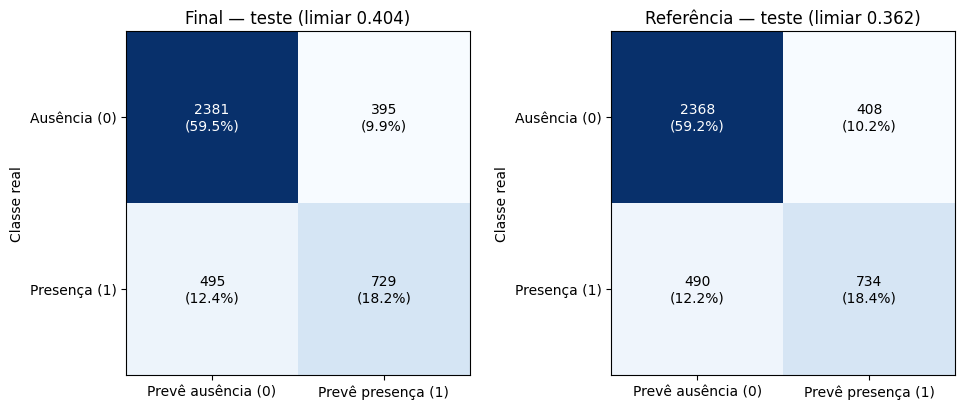

In [8]:
METRICAS_CLF = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC", "Average_Precision", "Log_Loss", "Brier"]
linhas = []
for papel, rotulo in (("final", "Final"), ("referencia", "Referência")):
    for c in CONJUNTOS:
        m = MET[("classificacao", papel, c)]
        linhas.append({"Modelo": rotulo, "Conjunto": NOME_CONJUNTO[c], "Limiar": m["limiar"],
                       **{k: m[k] for k in METRICAS_CLF}})
tabela_clf = pd.DataFrame(linhas)
display(tabela_clf.style.format(precision=4).hide(axis="index"))

fig, eixos = plt.subplots(1, 2, figsize=(10, 4.2))
for eixo, (papel, rotulo) in zip(eixos, (("final", "Final"), ("referencia", "Referência"))):
    m = MET[("classificacao", papel, "teste")]
    cm = m["Confusion_Matrix"]
    eixo.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            eixo.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm.sum():.1%})", ha="center", va="center",
                      color="white" if cm[i, j] > cm.max() / 2 else "black")
    eixo.set_xticks([0, 1], ["Prevê ausência (0)", "Prevê presença (1)"])
    eixo.set_yticks([0, 1], ["Ausência (0)", "Presença (1)"])
    eixo.set_ylabel("Classe real")
    eixo.set_title(f"{rotulo} — teste (limiar {m['limiar']:.3f})")
fig.tight_layout()
fig.savefig(pasta_figuras / "avaliacao_matriz_confusao_teste.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close(fig)

**Accuracy e desbalanceamento.** A tabela abaixo compara o modelo final com um classificador que prevê sempre a classe majoritária (ausência). Como a classe negativa é a maioria, esse classificador já tem Accuracy alta, embora não identifique nenhum caso positivo.

**Efeito do limiar no teste.** Para mostrar o compromisso entre Precision e Recall, as métricas do teste também são calculadas com o limiar padrão de 0,5. Essa comparação é apenas descritiva: o limiar usado é o escolhido na validação.

In [9]:
y_t = Y[("classificacao", "teste")]
prevalencia_teste = y_t.mean()
linhas = [{"Modelo": "Sempre ausência (classe majoritária)", "Limiar": np.nan,
           "Accuracy": 1 - prevalencia_teste, "Precision": 0.0, "Recall": 0.0, "F1-score": 0.0}]
for papel, rotulo in (("final", "Final"), ("referencia", "Referência")):
    for nome, limiar in (("escolhido na validação", MODELOS[("classificacao", papel)][1]["limiar"]), ("0,5", 0.5)):
        m = metricas.calcular_metricas_classificacao(y_t, SAIDAS[("classificacao", papel, "teste")], limiar)
        linhas.append({"Modelo": f"{rotulo} — limiar {nome}", "Limiar": limiar,
                       **{k: m[k] for k in ("Accuracy", "Precision", "Recall", "F1-score")}})
tabela_limiar_teste = pd.DataFrame(linhas)
print(f"Prevalência da classe positiva no teste: {prevalencia_teste:.4f}")
display(tabela_limiar_teste.style.format(precision=4, na_rep="—").hide(axis="index"))

Prevalência da classe positiva no teste: 0.3060


Modelo,Limiar,Accuracy,Precision,Recall,F1-score
Sempre ausência (classe majoritária),—,0.6940,0.0000,0.0000,0.0000
Final — limiar escolhido na validação,0.4038,0.7775,0.6486,0.5956,0.6210
"Final — limiar 0,5",0.5000,0.7815,0.6667,0.5719,0.6157
Referência — limiar escolhido na validação,0.3621,0.7755,0.6427,0.5997,0.6205
"Referência — limiar 0,5",0.5000,0.7833,0.6745,0.5637,0.6142


**Leitura.** O modelo final e a referência têm desempenho praticamente igual: no teste, AP próxima de 0,69 e ROC-AUC próxima de 0,80. As métricas que não dependem do limiar quase não mudam entre validação e teste na AP, enquanto a ROC-AUC do teste fica cerca de 0,02 abaixo da validação, diferença analisada na Seção 4.2.

**Accuracy.** O classificador que prevê sempre "ausência" já alcança Accuracy próxima de 0,69, apenas cerca de 8 pontos percentuais abaixo da rede, embora não identifique nenhum caso de doença. A Accuracy da rede, próxima de 0,78, esconde que cerca de 4 em cada 10 casos positivos do teste não são identificados (Recall próximo de 0,60), como mostra a matriz de confusão. Por isso ela não é usada como métrica principal.

**Limiar.** No teste, o limiar escolhido na validação produz o efeito esperado em relação a 0,5: Recall maior e Precision menor, com F1-score ligeiramente maior. O ganho de F1 é menor que o observado na validação, o que é esperado, porque o limiar foi otimizado na própria validação. As métricas que dependem do limiar caem um pouco mais entre validação e teste do que a AP, pelo mesmo motivo.

### 2.3 Curvas ROC, Precision–Recall e calibração

As curvas são calculadas no teste a partir das probabilidades da rede (sigmoide do logit). Na curva ROC, a diagonal corresponde a um classificador sem informação (ROC-AUC = 0,5); na curva Precision–Recall, a linha horizontal na prevalência corresponde ao mesmo caso (AP igual à prevalência). O ponto marcado em cada curva é o ponto de operação do limiar congelado.

A **curva de calibração** agrupa os registros em dez faixas com o mesmo número de registros (quantis da probabilidade prevista) e compara, em cada faixa, a probabilidade média prevista com a proporção observada de positivos. Pontos próximos da diagonal indicam probabilidades compatíveis com as frequências observadas; a curva é descritiva e, com dez faixas, cada ponto tem incerteza amostral.

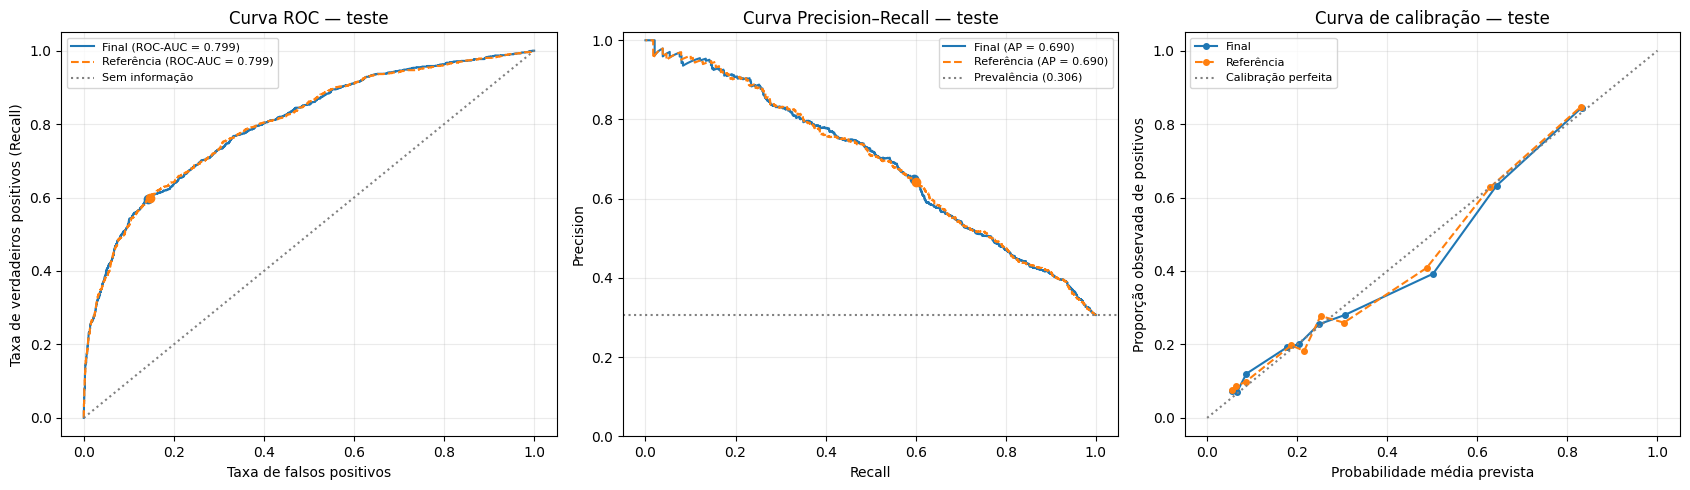

Final: probabilidade média prevista no teste = 0.3119 | prevalência observada = 0.3060
Referência: probabilidade média prevista no teste = 0.3108 | prevalência observada = 0.3060


In [10]:
fig, eixos = plt.subplots(1, 3, figsize=(17, 5))
for papel, rotulo, estilo in (("final", "Final", "-"), ("referencia", "Referência", "--")):
    prob = SAIDAS[("classificacao", papel, "teste")]
    m = MET[("classificacao", papel, "teste")]
    fpr, tpr, _ = roc_curve(y_t, prob)
    eixos[0].plot(fpr, tpr, estilo, label=f"{rotulo} (ROC-AUC = {m['ROC-AUC']:.3f})")
    cm = m["Confusion_Matrix"]
    eixos[0].plot(cm[0, 1] / cm[0].sum(), cm[1, 1] / cm[1].sum(), "o", color=eixos[0].lines[-1].get_color())
    prec, rec, _ = precision_recall_curve(y_t, prob)
    eixos[1].plot(rec, prec, estilo, label=f"{rotulo} (AP = {m['Average_Precision']:.3f})")
    eixos[1].plot(m["Recall"], m["Precision"], "o", color=eixos[1].lines[-1].get_color())
    frac_pos, prob_media = calibration_curve(y_t, prob, n_bins=10, strategy="quantile")
    eixos[2].plot(prob_media, frac_pos, estilo + "o", markersize=4, label=rotulo)
eixos[0].plot([0, 1], [0, 1], ":", color="gray", label="Sem informação")
eixos[0].set(xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos (Recall)", title="Curva ROC — teste")
eixos[1].axhline(prevalencia_teste, linestyle=":", color="gray", label=f"Prevalência ({prevalencia_teste:.3f})")
eixos[1].set(xlabel="Recall", ylabel="Precision", title="Curva Precision–Recall — teste", ylim=(0, 1.02))
eixos[2].plot([0, 1], [0, 1], ":", color="gray", label="Calibração perfeita")
eixos[2].set(xlabel="Probabilidade média prevista", ylabel="Proporção observada de positivos", title="Curva de calibração — teste")
for eixo in eixos:
    eixo.grid(alpha=0.25); eixo.legend(fontsize=8)
fig.tight_layout()
fig.savefig(pasta_figuras / "avaliacao_roc_pr_calibracao_teste.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close(fig)

for papel, rotulo in (("final", "Final"), ("referencia", "Referência")):
    print(f"{rotulo}: probabilidade média prevista no teste = {SAIDAS[('classificacao', papel, 'teste')].mean():.4f} "
          f"| prevalência observada = {prevalencia_teste:.4f}")

**Leitura.** As curvas do modelo final e da referência praticamente se sobrepõem: as duas redes ordenam os registros da mesma forma. A curva ROC fica bem acima da diagonal, e a curva Precision–Recall fica acima da prevalência em toda a extensão. Precision acima de 0,9 só é obtida com Recall baixo (até cerca de 0,2): a rede identifica com alta confiança apenas uma pequena parte dos casos positivos, e, para encontrar quase todos eles (Recall próximo de 0,9), a Precision cai para perto de 0,4. O ponto de operação do limiar congelado fica na região intermediária, com Recall próximo de 0,6.

**Calibração.** A probabilidade média prevista é próxima da prevalência observada, o que indica alinhamento agregado. Nas faixas de probabilidade baixa e alta, os pontos ficam próximos da diagonal. Na faixa intermediária (probabilidade prevista em torno de 0,5), a proporção observada de positivos fica perto de 0,4 nos dois modelos, isto é, as probabilidades parecem superestimar o risco nessa região. Cada ponto reúne cerca de 400 registros, e essa diferença é maior que a variação amostral esperada para uma proporção com esse número de registros; como se trata de uma única faixa, a leitura é indicativa. Uma recalibração (por exemplo, por regressão isotônica ajustada na validação) poderia corrigir esse desvio, mas não alteraria a ordenação nem a AP.

### 2.4 Escolha da métrica principal

**Regressão: RMSE e MAE.** O RMSE eleva os erros ao quadrado antes de calcular a média; por isso, penaliza mais os erros grandes e é mais sensível a *outliers*. O MAE dá o mesmo peso a todos os erros e é mais robusto. A razão RMSE/MAE indica quanto os erros grandes pesam: ela vale 1 quando todos os erros têm o mesmo tamanho e cerca de $\sqrt{\pi/2} \approx 1{,}25$ quando os resíduos seguem uma distribuição normal; valores bem maiores indicam caudas pesadas, isto é, alguns erros muito grandes. A tabela abaixo compara a distribuição dos resíduos do teste com a referência normal.

**Classificação: custos dos erros.** Em triagem cardiovascular, um falso negativo (pessoa com a doença classificada como saudável) tende a ser mais grave que um falso positivo (pessoa saudável encaminhada para exames adicionais). Por isso, a seleção usou a AP, que resume a curva Precision–Recall sem depender de limiar e se concentra na classe positiva, e o limiar foi definido na validação. A Accuracy não foi usada como métrica principal, pelos motivos mostrados na Seção 2.2.

In [11]:
y_r = Y[("regressao", "teste")]
linhas = []
for papel, rotulo in (("final", "Final"), ("referencia", "Referência")):
    e = y_r - SAIDAS[("regressao", papel, "teste")]
    m = MET[("regressao", papel, "teste")]
    dp = e.std(ddof=1)
    linhas.append({
        "Modelo": rotulo, "MAE": m["MAE"], "RMSE": m["RMSE"], "RMSE / MAE": m["RMSE"] / m["MAE"],
        "Média dos resíduos": e.mean(), "Desvio dos resíduos": dp,
        "Assimetria": stats.skew(e), "Curtose (excesso)": stats.kurtosis(e),
        "|resíduo| > 2 desvios (%)": 100 * np.mean(np.abs(e - e.mean()) > 2 * dp),
        "|resíduo| > 3 desvios (%)": 100 * np.mean(np.abs(e - e.mean()) > 3 * dp),
    })
linhas.append({"Modelo": "Distribuição normal (comparação)", "RMSE / MAE": np.sqrt(np.pi / 2), "Assimetria": 0.0, "Curtose (excesso)": 0.0,
               "|resíduo| > 2 desvios (%)": 100 * 2 * stats.norm.sf(2), "|resíduo| > 3 desvios (%)": 100 * 2 * stats.norm.sf(3)})
tabela_residuos = pd.DataFrame(linhas)
display(tabela_residuos.style.format(precision=4, na_rep="—").hide(axis="index"))

Modelo,MAE,RMSE,RMSE / MAE,Média dos resíduos,Desvio dos resíduos,Assimetria,Curtose (excesso),|resíduo| > 2 desvios (%),|resíduo| > 3 desvios (%)
Final,2.3854,2.9686,1.2445,-0.0164,2.9689,0.2488,-0.0791,4.3250,0.3000
Referência,2.3918,2.9751,1.2438,-0.0915,2.9740,0.2492,-0.0711,4.3250,0.3000
Distribuição normal (comparação),—,—,1.2533,—,—,0.0000,0.0000,4.5500,0.2700


**Leitura.** A razão RMSE/MAE dos resíduos do teste é praticamente igual à de uma distribuição normal, a curtose em excesso é próxima de zero e as proporções de resíduos além de 2 e 3 desvios coincidem com as da normal. A assimetria é levemente positiva: há um pouco mais de erros grandes de subestimação (valor real acima do previsto) do que de superestimação. Não há caudas pesadas: o erro está espalhado entre os registros, e não concentrado em poucos *outliers*.

Nessa situação, RMSE e MAE carregam essencialmente a mesma informação e ordenam os modelos da mesma forma (o modelo final tem erro ligeiramente menor que a referência nas duas métricas). O RMSE foi mantido como métrica principal por ser coerente com a perda usada no treinamento (MSE) e por penalizar mais os erros grandes, que, em uma estimativa de risco, são os mais preocupantes (por exemplo, subestimar muito o risco de um paciente). Como os resíduos não têm caudas pesadas, essa sensibilidade não distorce a avaliação. O MAE, próximo de 2,4 pontos, é a forma mais direta de comunicar o erro típico ao cliente.

### 2.5 Análise dos resíduos (regressão)

Os resíduos $e_i = y_i - \hat{y}_i$ são analisados no teste, na escala original do `Risk_Score`, para o modelo final. O gráfico **real versus previsto** mostra o quanto as previsões se aproximam da diagonal $\hat{y} = y$; o gráfico de **resíduos versus previsto** revela padrões sistemáticos (por exemplo, erros que crescem com o valor previsto ou que se concentram em uma faixa); o histograma mostra a forma da distribuição dos erros.

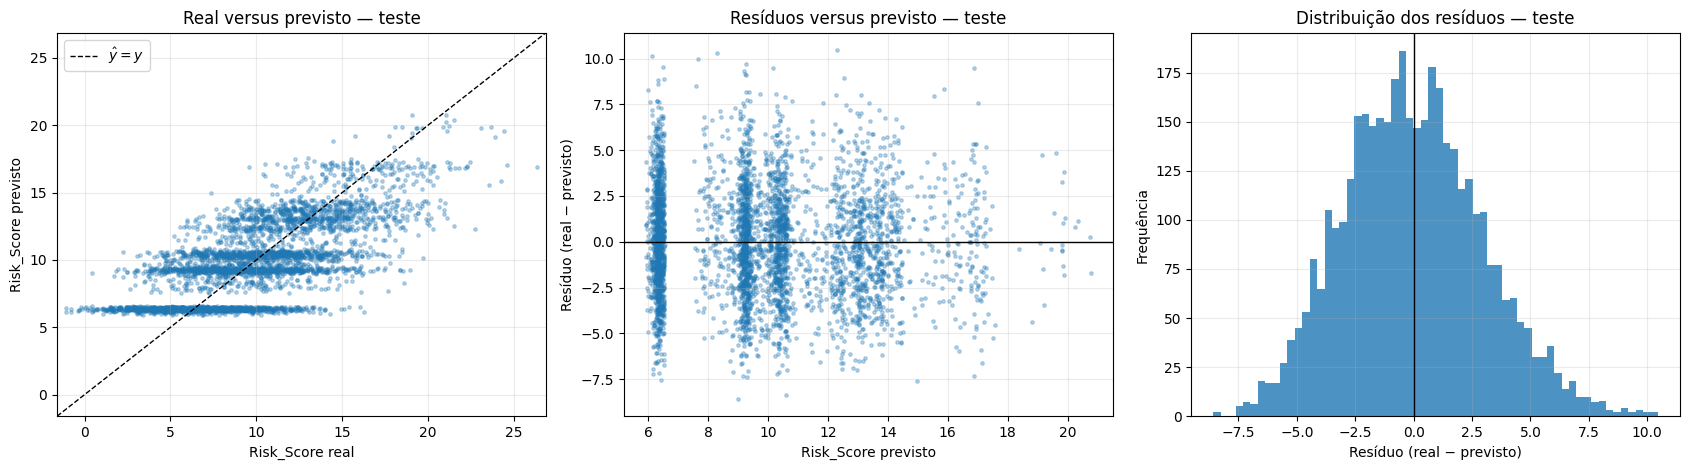

Risk_Score real no teste: mínimo -1.10, máximo 26.36
Risk_Score previsto no teste: mínimo 5.94, máximo 20.77


,n,media,desvio,RMSE
Faixa do valor previsto,,,,
"(5.943, 6.423]",800,0.0973,2.9739,2.9737
"(6.423, 9.218]",800,0.1762,3.0352,3.0385
"(9.218, 10.322]",800,0.0095,2.9455,2.9437
"(10.322, 12.852]",800,-0.2404,2.9950,3.0027
"(12.852, 20.771]",800,-0.1244,2.8810,2.8819


In [12]:
prev_r = SAIDAS[("regressao", "final", "teste")]
e = y_r - prev_r
fig, eixos = plt.subplots(1, 3, figsize=(17, 4.8))
lim = (min(y_r.min(), prev_r.min()) - 0.5, max(y_r.max(), prev_r.max()) + 0.5)
eixos[0].scatter(y_r, prev_r, s=6, alpha=0.3)
eixos[0].plot(lim, lim, "--", color="black", linewidth=1, label="$\\hat{y} = y$")
eixos[0].set(xlim=lim, ylim=lim, xlabel="Risk_Score real", ylabel="Risk_Score previsto", title="Real versus previsto — teste")
eixos[1].scatter(prev_r, e, s=6, alpha=0.3)
eixos[1].axhline(0, color="black", linewidth=1)
eixos[1].set(xlabel="Risk_Score previsto", ylabel="Resíduo (real − previsto)", title="Resíduos versus previsto — teste")
eixos[2].hist(e, bins=60, color="tab:blue", alpha=0.8)
eixos[2].axvline(0, color="black", linewidth=1)
eixos[2].set(xlabel="Resíduo (real − previsto)", ylabel="Frequência", title="Distribuição dos resíduos — teste")
eixos[0].legend()
for eixo in eixos:
    eixo.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(pasta_figuras / "avaliacao_residuos_regressao_teste.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close(fig)

print(f"Risk_Score real no teste: mínimo {y_r.min():.2f}, máximo {y_r.max():.2f}")
print(f"Risk_Score previsto no teste: mínimo {prev_r.min():.2f}, máximo {prev_r.max():.2f}")
faixas = pd.qcut(prev_r, 5)
display(pd.DataFrame({"Faixa do valor previsto": faixas, "Resíduo": e}).groupby("Faixa do valor previsto", observed=True)["Resíduo"]
        .agg(n="size", media="mean", desvio="std", RMSE=lambda r: np.sqrt(np.mean(r ** 2)))
        .style.format(precision=4))

**Leitura.** As previsões se concentram em poucas faixas verticais (em torno de 6, de 9 a 10 e de 13). As quatro features binárias (diabetes, hipertensão, dor no peito e ECG) dividem os registros em grupos, e, dentro de cada grupo, a glicose e a pressão sistólica deslocam pouco a previsão. Na prática, a rede aprendeu principalmente um valor médio para cada combinação das variáveis binárias.

O gráfico real versus previsto mostra que as previsões ocupam uma faixa mais estreita que os valores reais: valores reais baixos tendem a ser superestimados e valores altos, subestimados. Esse padrão é a regressão à média esperada quando as features explicam cerca de metade da variância do alvo. Ele aparece também na média dos resíduos por faixa de valor previsto, levemente positiva nas faixas baixas e negativa nas altas, mas pequena em relação ao desvio dos resíduos. O RMSE é semelhante em todas as faixas, sem sinal marcado de heterocedasticidade, e o histograma é aproximadamente simétrico e centrado em zero.

O erro restante parece corresponder à variação do `Risk_Score` que não é explicada pelas seis features (a dispersão dentro de cada grupo), e não a uma falha sistemática que mais capacidade da rede pudesse corrigir. Isso é coerente com o patamar observado no estudo de hiperparâmetros.

## 3. Generalização

### 3.1 Gap entre treino, validação e teste

O gap é calculado como $\text{Gap} = \text{desempenho}_{\text{treino}} - \text{desempenho}_{\text{outro conjunto}}$. Para métricas de erro (RMSE), um gap **negativo** indica erro maior fora do treino; para métricas de qualidade (AP, R², ROC-AUC), um gap **positivo** indica desempenho pior fora do treino.

O tamanho do gap é lido em relação a uma referência de escala, que não é um teste estatístico: na regressão, o gap do preditor ingênuo, que não aprende relação nenhuma e mostra só o efeito de os conjuntos terem distribuições ligeiramente diferentes; na classificação, o gap de uma regressão logística ajustada no mesmo subconjunto, um modelo de baixa variância.

In [13]:
dt_c = treino.preparar_dados_tarefa(dados, "classificacao", incluir_teste=True)
logistica = LogisticRegression(max_iter=1000).fit(dt_c["X"]["ajuste"], dt_c["y_original"]["ajuste"])

def linha_gap(problema, rotulo, valores, secundaria):
    nome = "RMSE" if problema == "regressao" else "AP"
    nome2 = "R²" if problema == "regressao" else "ROC-AUC"
    return {"Problema": problema, "Modelo": rotulo,
            f"Métrica": nome,
            "Treino": valores["ajuste"], "Validação": valores["validacao"], "Teste": valores["teste"],
            "Gap treino − validação": valores["ajuste"] - valores["validacao"],
            "Gap treino − teste": valores["ajuste"] - valores["teste"],
            f"Secundária": nome2,
            "Sec. treino": secundaria["ajuste"], "Sec. teste": secundaria["teste"],
            "Gap sec. treino − teste": secundaria["ajuste"] - secundaria["teste"]}

linhas = []
for papel, rotulo in (("final", "Final"), ("referencia", "Referência")):
    linhas.append(linha_gap("regressao", rotulo,
                            {c: MET[("regressao", papel, c)]["RMSE"] for c in CONJUNTOS},
                            {c: MET[("regressao", papel, c)]["R2"] for c in CONJUNTOS}))
ing = {c: metricas.calcular_metricas_regressao(Y[("regressao", c)], np.full(len(Y[("regressao", c)]), media_ajuste)) for c in CONJUNTOS}
linhas.append(linha_gap("regressao", "Ingênuo (escala)", {c: ing[c]["RMSE"] for c in CONJUNTOS}, {c: ing[c]["R2"] for c in CONJUNTOS}))
for papel, rotulo in (("final", "Final"), ("referencia", "Referência")):
    linhas.append(linha_gap("classificacao", rotulo,
                            {c: MET[("classificacao", papel, c)]["Average_Precision"] for c in CONJUNTOS},
                            {c: MET[("classificacao", papel, c)]["ROC-AUC"] for c in CONJUNTOS}))
log_m = {c: metricas.calcular_metricas_classificacao(dt_c["y_original"][c], logistica.predict_proba(dt_c["X"][c])[:, 1]) for c in CONJUNTOS}
linhas.append(linha_gap("classificacao", "Regressão logística (escala)",
                        {c: log_m[c]["Average_Precision"] for c in CONJUNTOS}, {c: log_m[c]["ROC-AUC"] for c in CONJUNTOS}))
tabela_gap = pd.DataFrame(linhas)
display(tabela_gap.style.format(precision=4).hide(axis="index"))

Problema,Modelo,Métrica,Treino,Validação,Teste,Gap treino − validação,Gap treino − teste,Secundária,Sec. treino,Sec. teste,Gap sec. treino − teste
regressao,Final,RMSE,2.9654,2.9522,2.9686,0.0132,-0.0032,R²,0.5023,0.4763,0.0260
regressao,Referência,RMSE,2.9664,2.9545,2.9751,0.0118,-0.0087,R²,0.5020,0.4740,0.0280
regressao,Ingênuo (escala),RMSE,4.2035,4.1549,4.1028,0.0486,0.1006,R²,0.0000,-0.0003,0.0003
classificacao,Final,AP,0.7007,0.6880,0.6900,0.0127,0.0107,ROC-AUC,0.8200,0.7993,0.0207
classificacao,Referência,AP,0.7035,0.6875,0.6900,0.0160,0.0135,ROC-AUC,0.8215,0.7994,0.0221
classificacao,Regressão logística (escala),AP,0.6931,0.6827,0.6850,0.0104,0.0081,ROC-AUC,0.8149,0.7968,0.0181


**Leitura.** **Regressão:** os gaps de RMSE são muito pequenos. Entre treino e validação, o gap é positivo (o erro de validação é ligeiramente menor que o de treino); entre treino e teste, é levemente negativo (erro de teste ligeiramente maior). Os dois têm a ordem de grandeza da variação entre sementes e são menores que os gaps do preditor ingênuo, que não aprende nenhuma relação e, mesmo assim, apresenta diferenças entre os conjuntos por causa da variância do alvo em cada um. O gap de R² entre treino e teste é explicado principalmente por essa diferença de variância, como discutido na Seção 2.1. Não há sinal de sobreajuste.

**Classificação:** o gap de AP entre treino e teste é de cerca de 0,01 nas duas redes, e o de ROC-AUC, de cerca de 0,02. Os gaps da regressão logística, um modelo de baixa variância, são da mesma ordem e apenas alguns milésimos menores. A rede, portanto, acrescenta pouca variância em relação a um modelo linear; o gap do modelo final é ligeiramente menor que o da referência, o que é compatível com o efeito da regularização L2, mas a diferença é da ordem da variação entre sementes. No teste, a rede supera a regressão logística por margem pequena, o que indica que a não linearidade acrescenta pouco a estes dados.

### 3.2 Curvas de aprendizado do modelo final

As curvas mostram a perda de treino e de validação por época, para a configuração final na semente do modelo salvo. Elas foram gravadas durante o estudo de hiperparâmetros; como o retreinamento no Notebook 06 reproduziu exatamente a métrica de validação dessa execução, as curvas correspondem ao modelo salvo (a época do melhor estado é conferida com a registrada no checkpoint). A linha vertical marca a época do melhor estado, restaurado pelo *early stopping*; o treinamento continua até a paciência se esgotar.

Na regressão, a perda é o MSE do alvo padronizado; na classificação, a entropia cruzada binária. A perda de treino de cada época é a média dos lotes durante a época.

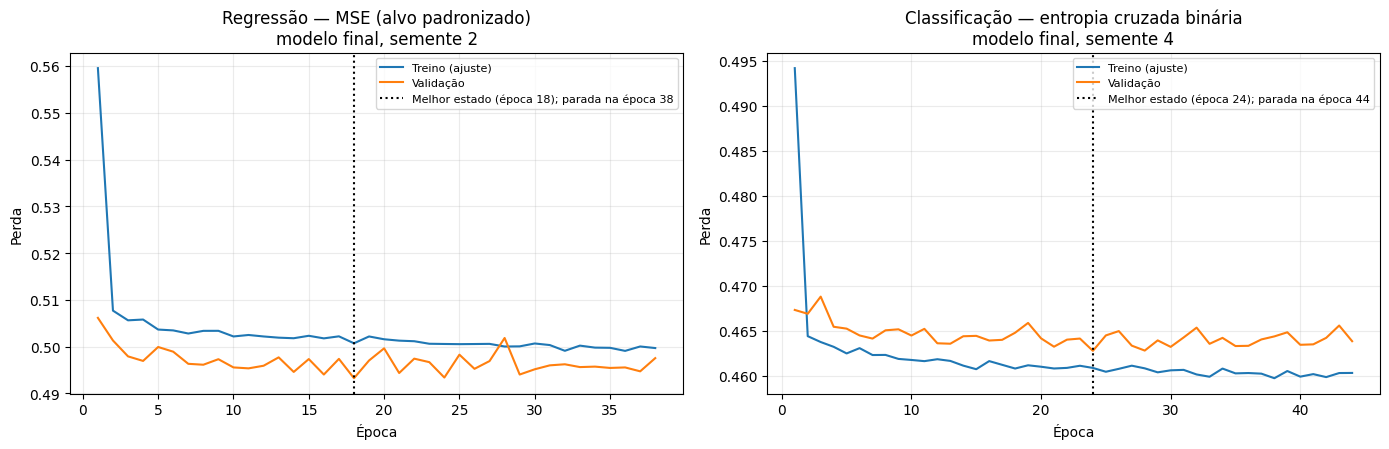

In [14]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.6))
for eixo, problema, titulo in zip(eixos, ("regressao", "classificacao"),
                                  ("Regressão — MSE (alvo padronizado)", "Classificação — entropia cruzada binária")):
    meta = MODELOS[(problema, "final")][1]["metadados"]
    curva = treino.carregar_curva(pasta_logs / "curvas_estudo", problema, meta["config_id"], meta["semente"])
    assert curva["epoca_melhor"] == meta["epoca_melhor"], "A curva não corresponde ao modelo salvo."
    epocas = np.arange(1, len(curva["hist"]["val"]) + 1)
    eixo.plot(epocas, curva["hist"]["treino"], label="Treino (ajuste)")
    eixo.plot(epocas, curva["hist"]["val"], label="Validação")
    eixo.axvline(meta["epoca_melhor"], color="black", linestyle=":",
                 label=f"Melhor estado (época {meta['epoca_melhor']}); parada na época {len(epocas)}")
    eixo.set(xlabel="Época", ylabel="Perda", title=f"{titulo}\nmodelo final, semente {meta['semente']}")
    eixo.grid(alpha=0.25); eixo.legend(fontsize=8)
fig.tight_layout()
fig.savefig(pasta_figuras / "generalizacao_curvas_modelo_final.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close(fig)

**Leitura.** Nos dois problemas, a perda cai bruscamente nas primeiras épocas e se estabiliza em um patamar; quase todo o aprendizado ocorre no início do treinamento.

Na **regressão**, a perda de validação fica abaixo da de treino em todas as épocas. Duas explicações são compatíveis com isso: a perda de treino é a média calculada durante a época, enquanto os pesos ainda mudam, e o alvo da validação tem variância um pouco menor que o do ajuste (como mostra o preditor ingênuo na Seção 3.1). Não é sinal de problema. A perda de validação oscila em torno de um patamar, e o melhor estado aparece em uma dessas oscilações.

Na **classificação**, a perda de treino continua diminuindo lentamente, enquanto a de validação permanece estável, com oscilações; a distância entre elas cresce pouco ao longo das épocas. É um sinal leve de aumento de variância, sem que a perda de validação passe a subir de forma sistemática dentro das épocas observadas.

Nos dois casos, o *early stopping* interrompe o treinamento no patamar. Como a curva de validação é praticamente plana nessa região, a época exata do melhor estado depende em parte das oscilações, e outras épocas do patamar produziriam desempenho semelhante.

### 3.3 Diagnóstico das configurações extremas

O modelo final, a referência e os valores extremos do estudo de hiperparâmetros são classificados como subajuste, sobreajuste ou bem ajustados, com as métricas de ajuste e de validação já registradas no Notebook 05 (cinco sementes; nenhum treinamento novo e nenhum uso do teste).

**Critério, definido antes da leitura dos resultados.** Para cada configuração, calcula-se a diferença das médias em relação à referência, orientada de modo que valores positivos significam **piora** (RMSE maior ou AP menor), no ajuste ($d_{aj}$) e na validação ($d_{val}$). Cada diferença é dividida pelo **desvio típico entre sementes** do problema e do conjunto (mediana dos desvios entre sementes das configurações dos estudos isolados, sem as que colapsaram), gerando $z_{aj}$ e $z_{val}$. Diferenças de até 2 desvios típicos não são tratadas como efeito.

1. **Falha de otimização:** alguma semente colapsou — divergência numérica ou desempenho de validação no nível de um preditor sem informação (RMSE não menor que o do preditor ingênuo; AP não maior que a prevalência; tolerância de 0,001, a mesma da triagem do Notebook 05). O mecanismo é a falha do treinamento, e não a capacidade do modelo.
2. **Subajuste:** piora no ajuste **e** na validação ($z_{aj} > 2$ e $z_{val} > 2$).
3. **Sobreajuste:** melhora no ajuste e piora na validação ($z_{aj} < -2$ e $z_{val} > 2$).
4. **Bem ajustado (na faixa da referência):** ajuste e validação sem diferença distinguível da referência ($|z_{aj}| \le 2$ e $|z_{val}| \le 2$).
5. **Indicativo:** combinações que não se encaixam nos casos anteriores; a leitura é descrita na própria tabela.

**Nota sobre o desvio típico.** Na primeira execução deste notebook, o desvio típico foi calculado como a raiz da média das variâncias entre sementes, agrupando todas as configurações dos estudos isolados. Na classificação, poucas configurações instáveis, com desvio entre sementes dezenas de vezes maior que o da referência, dominaram essa média: a faixa de 2 desvios típicos ficou maior que quase todas as diferenças observadas, e o critério se tornou insensível. A mediana não é dominada por essas configurações e fica próxima do desvio entre sementes da referência. A troca foi feita depois da primeira execução e é declarada aqui; na regressão, ela altera apenas o diagnóstico do lote completo, que passa de indicativo a subajuste.

Os critérios 2 a 4 são **relativos à referência**. O nível absoluto da referência e do modelo final é avaliado na Seção 3.1, em comparação com o preditor ingênuo e com a regressão logística.

In [15]:
log = treino.carregar_log(pasta_logs / "hiperparametros.csv")
with open(pasta_logs / "configuracao_final.json", encoding="utf-8") as f:
    CONFIG_FINAL = json.load(f)

ESTUDOS_ISOLADOS = {
    "hidden": [(v, v) for v in (2, 4, 8, 16, 32, 64, 128)] + [(32,) * v for v in (1, 2, 3, 5)],
    "activation": ["ReLU", "LeakyReLU", "Tanh", "Sigmoid", "GELU"],
    "otimizador": ["SGD", "SGD_momentum", "RMSprop", "Adam", "AdamW"],
    "lr": [1e-4, 1e-3, 1e-2, 1e-1, 1.0],
    "batch_size": [8, 32, 128, 512, 12800],
    "weight_decay": [0.0, 1e-5, 1e-4, 1e-3, 1e-2],
    "dropout": [0.0, 0.1, 0.3, 0.5],
}
ids_isolados = {treino.id_configuracao(treino.config_completa({k: v})) for k, vs in ESTUDOS_ISOLADOS.items() for v in vs}
ID_REF = treino.id_configuracao(treino.config_completa({}))

EXTREMOS = [
    ("Referência", "—", ID_REF),
    ("Final", "wd 1e-3", CONFIG_FINAL["regressao"]["config_id"]),   # mesma configuração nos dois problemas
    ("Neurônios por camada", "2", {"hidden": (2, 2)}), ("Neurônios por camada", "128", {"hidden": (128, 128)}),
    ("Camadas ocultas", "1", {"hidden": (32,)}), ("Camadas ocultas", "5", {"hidden": (32,) * 5}),
    ("Tamanho do batch", "8", {"batch_size": 8}), ("Tamanho do batch", "12.800 (completo)", {"batch_size": 12800}),
    ("Taxa de aprendizado", "1e-4", {"lr": 1e-4}), ("Taxa de aprendizado", "1", {"lr": 1.0}),
    ("Dropout", "0,5", {"dropout": 0.5}), ("Weight decay", "1e-2", {"weight_decay": 1e-2}),
]
assert CONFIG_FINAL["regressao"]["config_id"] == CONFIG_FINAL["classificacao"]["config_id"]

NOME_METRICA = {"regressao": "RMSE", "classificacao": "Average_Precision"}
limite_colapso = {
    "regressao": metricas.calcular_metricas_regressao(
        Y[("regressao", "validacao")], np.full(len(Y[("regressao", "validacao")]), media_ajuste))["RMSE"] - 0.001,
    "classificacao": Y[("classificacao", "validacao")].mean() + 0.001,
}

def colapsou(problema, l):
    v = l[f"{NOME_METRICA[problema]}_validacao"]
    ruim = (v >= limite_colapso[problema]) if problema == "regressao" else (v <= limite_colapso[problema])
    return (l["divergiu"].astype(bool) | v.isna() | ruim)

def diagnostico(z_aj, z_val, n_colapso):
    if n_colapso > 0:
        return f"Falha de otimização ({n_colapso} de 5 sementes)"
    if z_aj > 2 and z_val > 2:
        return "Subajuste"
    if z_aj < -2 and z_val > 2:
        return "Sobreajuste"
    if abs(z_aj) <= 2 and abs(z_val) <= 2:
        return "Bem ajustado (na faixa da referência)"
    if z_aj < -2 and abs(z_val) <= 2:
        return "Indicativo: ajuste melhor, validação estável (variância maior contida pelo early stopping)"
    if z_aj > 2 and abs(z_val) <= 2:
        return "Indicativo: ajuste pior, sem efeito distinguível na validação"
    if abs(z_aj) <= 2 and z_val > 2:
        return "Indicativo: validação pior, sem mudança distinguível no ajuste"
    return "Indicativo: validação melhor que a referência"

tabelas_extremos, DESVIO_TIPICO = {}, {}
for problema in ("regressao", "classificacao"):
    nome = NOME_METRICA[problema]
    lp = log[log["problema"] == problema]
    sinal = 1.0 if problema == "regressao" else -1.0             # orienta: positivo = piora
    iso = lp[lp["config_id"].isin(ids_isolados)]
    validas = [cid for cid, g in iso.groupby("config_id") if not colapsou(problema, g).any()]
    iso = iso[iso["config_id"].isin(validas)]
    DESVIO_TIPICO[problema] = {c: float(iso.groupby("config_id")[f"{nome}_{c}"].std(ddof=1).median())
                               for c in ("ajuste", "validacao")}
    ref = lp[lp["config_id"] == ID_REF]
    linhas = []
    for hiper, valor, cfg in EXTREMOS:
        cid = cfg if isinstance(cfg, str) else treino.id_configuracao(treino.config_completa(cfg))
        l = lp[lp["config_id"] == cid]
        assert len(l) == 5, (problema, hiper, valor, len(l))
        n_col = int(colapsou(problema, l).sum())
        d = {c: sinal * (l[f"{nome}_{c}"].mean() - ref[f"{nome}_{c}"].mean()) for c in ("ajuste", "validacao")}
        z = {c: d[c] / DESVIO_TIPICO[problema][c] for c in d}
        linhas.append({
            "Hiperparâmetro": hiper, "Valor": valor, "Parâmetros": int(l["n_parametros"].iloc[0]),
            "Ajuste (média)": l[f"{nome}_ajuste"].mean(), "Ajuste (desvio)": l[f"{nome}_ajuste"].std(ddof=1),
            "Validação (média)": l[f"{nome}_validacao"].mean(), "Validação (desvio)": l[f"{nome}_validacao"].std(ddof=1),
            "Gap ajuste − validação": (l[f"{nome}_ajuste"] - l[f"{nome}_validacao"]).mean(),
            "Época do melhor estado (média)": l["epoca_melhor"].mean(),
            "z ajuste": z["ajuste"], "z validação": z["validacao"],
            "Diagnóstico": diagnostico(z["ajuste"], z["validacao"], n_col),
        })
    tabelas_extremos[problema] = pd.DataFrame(linhas)
    print(f"\n{'REGRESSÃO — RMSE' if problema == 'regressao' else 'CLASSIFICAÇÃO — AP'} "
          f"(desvio típico entre sementes: ajuste {DESVIO_TIPICO[problema]['ajuste']:.4f}; "
          f"validação {DESVIO_TIPICO[problema]['validacao']:.4f})")
    display(tabelas_extremos[problema].style.format(precision=4).format({"Época do melhor estado (média)": "{:.1f}",
            "z ajuste": "{:+.1f}", "z validação": "{:+.1f}"}).hide(axis="index"))


REGRESSÃO — RMSE (desvio típico entre sementes: ajuste 0.0043; validação 0.0023)


Hiperparâmetro,Valor,Parâmetros,Ajuste (média),Ajuste (desvio),Validação (média),Validação (desvio),Gap ajuste − validação,Época do melhor estado (média),z ajuste,z validação,Diagnóstico
Referência,—,1313,2.959918,0.005699,2.954775,0.002824,0.005143,21.2,+0.0,+0.0,Bem ajustado (na faixa da referência)
Final,wd 1e-3,1313,2.963006,0.001910,2.951818,0.002726,0.011188,45.6,+0.7,-1.3,Bem ajustado (na faixa da referência)
Neurônios por camada,2,23,3.004639,0.004892,2.970159,0.005127,0.034480,34.8,+10.5,+6.7,Subajuste
Neurônios por camada,128,17537,2.956329,0.007585,2.955194,0.001001,0.001135,21.8,-0.8,+0.2,Bem ajustado (na faixa da referência)
Camadas ocultas,1,257,2.967361,0.006213,2.953741,0.001858,0.013620,33.2,+1.7,-0.5,Bem ajustado (na faixa da referência)
Camadas ocultas,5,4481,2.958456,0.004960,2.955629,0.001902,0.002827,25.0,-0.3,+0.4,Bem ajustado (na faixa da referência)
Tamanho do batch,8,1313,2.962952,0.007395,2.954904,0.001601,0.008048,16.4,+0.7,+0.1,Bem ajustado (na faixa da referência)
Tamanho do batch,12.800 (completo),1313,2.978250,0.003323,2.960611,0.003377,0.017638,200.0,+4.3,+2.6,Subajuste
Taxa de aprendizado,1e-4,1313,2.965357,0.004213,2.954785,0.001958,0.010572,75.0,+1.3,+0.0,Bem ajustado (na faixa da referência)
Taxa de aprendizado,1,1313,3.855354,0.454622,3.809475,0.447543,0.045879,8.2,+209.5,+373.8,Falha de otimização (1 de 5 sementes)



CLASSIFICAÇÃO — AP (desvio típico entre sementes: ajuste 0.0017; validação 0.0014)


Hiperparâmetro,Valor,Parâmetros,Ajuste (média),Ajuste (desvio),Validação (média),Validação (desvio),Gap ajuste − validação,Época do melhor estado (média),z ajuste,z validação,Diagnóstico
Referência,—,1313,0.701983,0.003031,0.686916,0.001316,0.015068,13.4,-0.0,-0.0,Bem ajustado (na faixa da referência)
Final,wd 1e-3,1313,0.700849,0.000904,0.688244,0.001281,0.012605,29.0,+0.7,-1.0,Bem ajustado (na faixa da referência)
Neurônios por camada,2,23,0.615913,0.173240,0.607795,0.168747,0.008118,62.4,+49.5,+58.6,Falha de otimização (1 de 5 sementes)
Neurônios por camada,128,17537,0.701001,0.003792,0.685919,0.001350,0.015082,5.8,+0.6,+0.7,Bem ajustado (na faixa da referência)
Camadas ocultas,1,257,0.701013,0.001889,0.687388,0.000854,0.013625,28.4,+0.6,-0.3,Bem ajustado (na faixa da referência)
Camadas ocultas,5,4481,0.701538,0.002820,0.685719,0.001357,0.015819,8.2,+0.3,+0.9,Bem ajustado (na faixa da referência)
Tamanho do batch,8,1313,0.702823,0.001316,0.685084,0.001523,0.017740,11.0,-0.5,+1.4,Bem ajustado (na faixa da referência)
Tamanho do batch,12.800 (completo),1313,0.698745,0.000583,0.685439,0.002181,0.013306,200.0,+1.9,+1.1,Bem ajustado (na faixa da referência)
Taxa de aprendizado,1e-4,1313,0.700540,0.001738,0.687027,0.001489,0.013513,56.0,+0.8,-0.1,Bem ajustado (na faixa da referência)
Taxa de aprendizado,1,1313,0.306016,0.000000,0.305937,0.000000,0.000078,8.4,+227.9,+282.1,Falha de otimização (5 de 5 sementes)


**Leitura.** **Regressão:** são classificados como **subajuste** a rede com 2 neurônios por camada (capacidade insuficiente), o *dropout* de 0,5 e o *weight decay* de $10^{-2}$ (regularização excessiva, que reduz a capacidade efetiva) e o lote completo (apenas uma atualização por época: o melhor estado ocorre na última época, ou seja, o treinamento termina sem convergir). Nos quatro casos, o erro aumenta no ajuste e na validação. A taxa de aprendizado igual a 1 aparece como **falha de otimização**: pelo critério, uma semente atingiu o nível do preditor ingênuo, mas todas tiveram erro muito maior que a referência e grande variação entre si.

**Classificação:** os únicos casos fora da faixa da referência são **falhas de otimização**: a rede com 2 neurônios colapsou em uma das cinco sementes, e a taxa igual a 1 produziu saída constante em todas. O *weight decay* de $10^{-2}$ reduz o desempenho no ajuste sem efeito distinguível na validação (indicativo). Os demais extremos ficam na faixa da referência, o que é coerente com a menor sensibilidade da AP observada no estudo de hiperparâmetros.

**Nenhum extremo foi classificado como sobreajuste.** As redes de maior capacidade (128 neurônios, com mais parâmetros do que registros de ajuste, e 5 camadas) têm desempenho de ajuste e de validação na faixa da referência; na classificação, atingem o melhor estado mais cedo, o que indica que se ajustam mais depressa ao subconjunto de treino, mas o *early stopping* devolve o estado anterior a qualquer piora na validação. Além disso, as quatro features binárias definem apenas 16 combinações, e as duas numéricas trazem sinal limitado: há pouca estrutura a ser memorizada além do ruído, e o *early stopping* interrompe o treinamento antes que isso aconteça. Para observar sobreajuste clássico, seria necessário treinar sem *early stopping*, o que não faz parte do protocolo.

O **modelo final** e a **referência** são classificados como bem ajustados: as métricas de ajuste, validação e teste são próximas, o desempenho é muito superior ao do preditor ingênuo e semelhante ao da regressão logística (Seção 3.1), e as curvas de aprendizado não mostram aumento sistemático da perda de validação (Seção 3.2). A limitação do desempenho vem da informação contida nas features, e não de subajuste ou sobreajuste da rede.

### 3.4 Viés e variância


**Capacidade.** Aumentar a capacidade de 2 para cerca de 16 neurônios por camada reduz o viés: a rede com 2 neurônios subajusta nos dois problemas. A partir daí, mais neurônios ou camadas não reduzem o erro de validação. O viés que permanece, portanto, não se deve à capacidade da rede, e sim à informação disponível nas seis features: em relação a elas, o erro restante se comporta como irredutível (Seção 2.5). Mais capacidade aumenta os sinais de variância — melhor estado alcançado mais cedo e, na regressão, erro de ajuste ligeiramente menor, dentro da variação entre sementes —, mas o *early stopping* impede que isso piore a validação.

**Regularização.** *Dropout* de 0,5 e *weight decay* de $10^{-2}$ aumentam o viés (subajuste na regressão) sem benefício na validação, porque há pouca variância a reduzir. A regularização L2 leve da configuração final ($10^{-3}$) altera o desempenho dentro da variação entre sementes; o gap ligeiramente menor e a variação entre sementes um pouco menor no teste (Seção 4.1) são compatíveis com uma pequena redução de variância.

**Otimização.** Os piores resultados do estudo vêm de falhas de otimização (taxa de aprendizado igual a 1, lote completo com 200 atualizações, colapso de redes muito estreitas), e não do compromisso entre viés e variância propriamente dito.

**Conclusão.** A configuração final está em um patamar em que o erro é dominado pelo viés em relação às features disponíveis, e não pela variância. Modelos mais complexos não devem melhorar o desempenho; ganhos dependeriam de features mais informativas.

## 4. Análises complementares

As análises desta seção **não fazem parte da avaliação principal** e não foram usadas para escolher ou alterar modelos, sementes ou limiares. Elas descrevem a robustez da configuração final.

### 4.1 Variação entre sementes no teste

O resultado principal corresponde a um único modelo por configuração (a semente mediana). Para separar a diferença entre o modelo final e a referência da variação causada pela inicialização dos pesos, as duas configurações são treinadas com as **mesmas cinco sementes** do estudo, pelo mesmo protocolo (subconjunto de ajuste, *early stopping* pela validação), e avaliadas no teste. Como as sementes são as mesmas, a comparação é feita também pela **diferença pareada** (final − referência) em cada semente.

O desvio entre sementes descreve a variação entre inicializações **neste conjunto de teste**; não é um intervalo de confiança nem mede a variação entre amostras de teste diferentes. Esta análise é um complemento de robustez, e não uma avaliação independente adicional.

São reportadas apenas métricas que não dependem de limiar, porque o limiar congelado foi escolhido para o modelo salvo. A semente do modelo salvo está entre as cinco: o seu resultado deve coincidir com o da avaliação principal, o que é conferido ao final (a coincidência exata exige o mesmo processador em que os modelos foram treinados). Esta seção treina 20 redes.

In [16]:
DT_TESTE = {p: treino.preparar_dados_tarefa(dados, p, incluir_teste=True) for p in ("regressao", "classificacao")}
CFG = {"final": treino.config_completa({**CONFIG_FINAL["regressao"]["config"],
                                        "hidden": tuple(CONFIG_FINAL["regressao"]["config"]["hidden"])}),
       "referencia": treino.config_completa({})}
assert treino.id_configuracao(CFG["final"]) == CONFIG_FINAL["regressao"]["config_id"]

METRICAS_SEMENTES = {"regressao": ["RMSE", "MAE", "R2"], "classificacao": ["Average_Precision", "ROC-AUC", "Log_Loss", "Brier"]}
linhas = []
for problema in ("regressao", "classificacao"):
    for papel in ("final", "referencia"):
        for semente in treino.SEMENTES:
            modelo, _, registro = treino.executar_configuracao(DT_TESTE[problema], CFG[papel], semente, device=DEVICE)
            assert not registro["divergiu"]
            m_teste = treino.metricas_conjunto(modelo, DT_TESTE[problema], "teste", DEVICE)
            linhas.append({"problema": problema, "papel": papel, "semente": semente,
                           f"{NOME_METRICA[problema]}_validacao": registro["metricas_validacao"][NOME_METRICA[problema]],
                           **{f"{k}_teste": m_teste[k] for k in METRICAS_SEMENTES[problema]}})
            print(f"{problema:13s} {papel:10s} semente {semente}: concluída")
tabela_sementes = pd.DataFrame(linhas)

regressao     final      semente 0: concluída
regressao     final      semente 1: concluída
regressao     final      semente 2: concluída
regressao     final      semente 3: concluída
regressao     final      semente 4: concluída
regressao     referencia semente 0: concluída
regressao     referencia semente 1: concluída
regressao     referencia semente 2: concluída
regressao     referencia semente 3: concluída
regressao     referencia semente 4: concluída
classificacao final      semente 0: concluída
classificacao final      semente 1: concluída
classificacao final      semente 2: concluída
classificacao final      semente 3: concluída
classificacao final      semente 4: concluída
classificacao referencia semente 0: concluída
classificacao referencia semente 1: concluída
classificacao referencia semente 2: concluída
classificacao referencia semente 3: concluída
classificacao referencia semente 4: concluída


In [17]:
for problema in ("regressao", "classificacao"):
    nome = NOME_METRICA[problema]
    t = tabela_sementes[tabela_sementes["problema"] == problema]
    colunas = [f"{nome}_validacao"] + [f"{k}_teste" for k in METRICAS_SEMENTES[problema]]
    print(f"\n{'REGRESSÃO' if problema == 'regressao' else 'CLASSIFICAÇÃO'} — resultados por semente")
    display(t.pivot(index="semente", columns="papel", values=colunas).style.format(precision=4))

    resumo = t.groupby("papel")[colunas].agg(["mean", lambda s: s.std(ddof=1)])
    resumo.columns = [f"{c} ({'média' if f == 'mean' else 'desvio'})" for c, f in resumo.columns]
    display(resumo.T.style.format(precision=4))

    f_ = t[t["papel"] == "final"].set_index("semente")[f"{nome}_teste"]
    r_ = t[t["papel"] == "referencia"].set_index("semente")[f"{nome}_teste"]
    dif = f_ - r_
    print(f"Diferença pareada no teste (final − referência), {nome}: "
          f"{' | '.join(f's{s}: {v:+.4f}' for s, v in dif.items())}")
    print(f"  média {dif.mean():+.4f} | desvio {dif.std(ddof=1):.4f} | "
          f"sementes em que o final é melhor: {int(((dif < 0) if problema == 'regressao' else (dif > 0)).sum())} de 5")

    for papel in ("final", "referencia"):
        semente_salva = MODELOS[(problema, papel)][1]["metadados"]["semente"]
        refeito = t[(t["papel"] == papel) & (t["semente"] == semente_salva)][f"{nome}_teste"].iloc[0]
        principal = MET[(problema, papel, "teste")][nome]
        print(f"  Conferência ({papel}, semente {semente_salva}): retreinado {refeito:.6f} | "
              f"modelo salvo {principal:.6f} | diferença {abs(refeito - principal):.2e}")


REGRESSÃO — resultados por semente


papel,final,referencia
RMSE_validacao (média),2.9518,2.9548
RMSE_validacao (desvio),0.0027,0.0028
RMSE_teste (média),2.9681,2.9697
RMSE_teste (desvio),0.0018,0.0045
MAE_teste (média),2.3843,2.3858
MAE_teste (desvio),0.0031,0.0037
R2_teste (média),0.4765,0.4759
R2_teste (desvio),0.0006,0.0016


Diferença pareada no teste (final − referência), RMSE: s0: -0.0032 | s1: +0.0023 | s2: -0.0014 | s3: -0.0081 | s4: +0.0020
  média -0.0017 | desvio 0.0043 | sementes em que o final é melhor: 3 de 5
  Conferência (final, semente 2): retreinado 2.968563 | modelo salvo 2.968563 | diferença 0.00e+00
  Conferência (referencia, semente 3): retreinado 2.975073 | modelo salvo 2.975073 | diferença 0.00e+00

CLASSIFICAÇÃO — resultados por semente


papel,final,referencia
Average_Precision_validacao (média),0.6882,0.6869
Average_Precision_validacao (desvio),0.0013,0.0013
Average_Precision_teste (média),0.6906,0.6898
Average_Precision_teste (desvio),0.0006,0.0017
ROC-AUC_teste (média),0.7999,0.7993
ROC-AUC_teste (desvio),0.0008,0.0006
Log_Loss_teste (média),0.4761,0.4760
Log_Loss_teste (desvio),0.0005,0.0005
Brier_teste (média),0.1541,0.1540
Brier_teste (desvio),0.0003,0.0002


Diferença pareada no teste (final − referência), Average_Precision: s0: +0.0005 | s1: -0.0012 | s2: +0.0023 | s3: +0.0013 | s4: +0.0007
  média +0.0007 | desvio 0.0013 | sementes em que o final é melhor: 4 de 5
  Conferência (final, semente 4): retreinado 0.690012 | modelo salvo 0.690012 | diferença 0.00e+00
  Conferência (referencia, semente 3): retreinado 0.689977 | modelo salvo 0.689977 | diferença 0.00e+00


**Leitura.** A variação entre sementes no teste é pequena nos dois problemas: o desvio do RMSE fica na casa dos milésimos e o da AP, abaixo de 0,002. As diferenças pareadas entre o modelo final e a referência têm média menor que o próprio desvio entre as sementes: na regressão, o final tem RMSE menor em 3 de 5 sementes; na classificação, AP maior em 4 de 5. Nenhuma das duas diferenças é distinguível da variação entre inicializações, o que confirma, agora no teste, a conclusão do estudo de hiperparâmetros: a configuração final equivale à referência com uma regularização leve, sem melhora demonstrada.

Nas métricas principais, o desvio entre sementes do modelo final é menor que o da referência nos dois problemas, o que é compatível com o efeito estabilizador da regularização L2; com apenas cinco sementes, porém, o próprio desvio é estimado com pouca precisão, e a observação é indicativa.

As diferenças entre validação e teste têm o mesmo sentido em todas as sementes (RMSE um pouco maior no teste; AP ligeiramente maior), o que indica uma característica das partições, e não de uma inicialização específica. A conferência mostra que a semente do modelo salvo, treinada novamente, reproduz exatamente o resultado da avaliação principal.

### 4.2 Validação cruzada *K-fold* da configuração final

A configuração final é avaliada por validação cruzada com cinco *folds* sobre os 16.000 registros de treino: `StratifiedKFold` na classificação e `KFold` na regressão, ambos embaralhados com `random_state=42`. Em cada *fold*:

1. o *fold* externo é separado para avaliação;
2. a parte restante é dividida em ajuste interno (80%) e validação interna (20%), estratificada pela classe cardiovascular, com `random_state=42`;
3. a imputação, a padronização das features e, na regressão, a padronização do alvo são ajustadas **somente no ajuste interno**;
4. a validação interna é usada **apenas** para o *early stopping*;
5. o modelo é avaliado uma única vez no *fold* externo.

Usa-se a semente do modelo salvo em todos os *folds*, com as métricas que não dependem de limiar e, na classificação, também o F1-score com o limiar congelado do modelo final, apenas como informação. O teste não participa desta análise.

**Leitura.** O desvio entre *folds* reflete a variação entre essas partições, e não uma estimativa independente de incerteza, porque os *folds* compartilham a maior parte dos dados de treinamento. A média tende a ser **ligeiramente otimista**, porque a configuração foi escolhida com a validação, que faz parte desses 16.000 registros. Em sentido contrário, cada modelo é treinado com cerca de 10.240 registros, menos que os 12.800 do modelo final. Esta seção treina 10 redes.

In [18]:
X_treino = dados["X_treino"]
y_treino_c, y_treino_r = dados["y_treino_c"], dados["y_treino_r"]
METRICAS_KFOLD = {"regressao": ["RMSE", "MAE", "R2"], "classificacao": ["Average_Precision", "ROC-AUC", "F1-score"]}
linhas = []
for problema in ("regressao", "classificacao"):
    cv = pipeline_data.criar_cv(problema)
    divisoes = cv.split(X_treino, y_treino_c) if problema == "classificacao" else cv.split(X_treino)
    semente = MODELOS[(problema, "final")][1]["metadados"]["semente"]
    limiar = MODELOS[("classificacao", "final")][1]["limiar"]
    for k, (pos_tr, pos_av) in enumerate(divisoes, start=1):
        idx_tr, idx_av = X_treino.index[pos_tr], X_treino.index[pos_av]
        interno = pipeline_data.dividir_ajuste_validacao(X_treino.loc[idx_tr], y_treino_c.loc[idx_tr], y_treino_r.loc[idx_tr])
        dados_fold = {**interno, "X_teste": X_treino.loc[idx_av],
                      "y_teste_c": y_treino_c.loc[idx_av], "y_teste_r": y_treino_r.loc[idx_av]}
        dt_fold = treino.preparar_dados_tarefa(dados_fold, problema, incluir_teste=True)
        modelo, _, registro = treino.executar_configuracao(dt_fold, CFG["final"], semente, device=DEVICE)
        assert not registro["divergiu"]
        m_aj = treino.metricas_conjunto(modelo, dt_fold, "ajuste", DEVICE, limiar)
        m_av = treino.metricas_conjunto(modelo, dt_fold, "teste", DEVICE, limiar)
        linhas.append({"problema": problema, "fold": k, "n_ajuste": len(interno["X_ajuste"]),
                       "n_validacao_interna": len(interno["X_validacao"]), "n_avaliacao": len(idx_av),
                       "epoca_melhor": registro["epoca_melhor"],
                       **{f"{m}_ajuste": m_aj[m] for m in METRICAS_KFOLD[problema]},
                       **{f"{m}_fold": m_av[m] for m in METRICAS_KFOLD[problema]}})
        print(f"{problema:13s} fold {k}: concluído")
tabela_kfold = pd.DataFrame(linhas)

regressao     fold 1: concluído
regressao     fold 2: concluído
regressao     fold 3: concluído
regressao     fold 4: concluído
regressao     fold 5: concluído
classificacao fold 1: concluído
classificacao fold 2: concluído
classificacao fold 3: concluído
classificacao fold 4: concluído
classificacao fold 5: concluído


In [19]:
resumo_kfold = []
for problema in ("regressao", "classificacao"):
    t = tabela_kfold[tabela_kfold["problema"] == problema]
    print(f"\n{'REGRESSÃO' if problema == 'regressao' else 'CLASSIFICAÇÃO'} — K-fold (5 folds)")
    colunas = ["n_ajuste", "n_validacao_interna", "n_avaliacao", "epoca_melhor"] + \
              [f"{m}_{c}" for m in METRICAS_KFOLD[problema] for c in ("ajuste", "fold")]
    display(t[["fold"] + colunas].style.format(precision=4).hide(axis="index"))
    for m in METRICAS_KFOLD[problema]:
        principal = MET[(problema, "final", "teste")][m]
        resumo_kfold.append({"Problema": problema, "Métrica": m,
                             "K-fold — média": t[f"{m}_fold"].mean(), "K-fold — desvio": t[f"{m}_fold"].std(ddof=1),
                             "K-fold — mínimo": t[f"{m}_fold"].min(), "K-fold — máximo": t[f"{m}_fold"].max(),
                             "Modelo salvo — teste": principal})
tabela_resumo_kfold = pd.DataFrame(resumo_kfold)
display(tabela_resumo_kfold.style.format(precision=4).hide(axis="index"))


REGRESSÃO — K-fold (5 folds)


fold,n_ajuste,n_validacao_interna,n_avaliacao,epoca_melhor,RMSE_ajuste,RMSE_fold,MAE_ajuste,MAE_fold,R2_ajuste,R2_fold
1,10240,2560,3200,26,2.9488,3.0118,2.3525,2.4348,0.5026,0.4751
2,10240,2560,3200,31,2.9545,2.9486,2.3786,2.3585,0.5012,0.5078
3,10240,2560,3200,12,2.9654,2.9253,2.3824,2.3549,0.5028,0.4989
4,10240,2560,3200,31,2.9414,3.0271,2.3672,2.4174,0.5020,0.4981
5,10240,2560,3200,37,2.9433,2.9954,2.3644,2.4160,0.5048,0.4907



CLASSIFICAÇÃO — K-fold (5 folds)


fold,n_ajuste,n_validacao_interna,n_avaliacao,epoca_melhor,Average_Precision_ajuste,Average_Precision_fold,ROC-AUC_ajuste,ROC-AUC_fold,F1-score_ajuste,F1-score_fold
1,10240,2560,3200,6,0.6976,0.6906,0.8178,0.8194,0.6379,0.6392
2,10240,2560,3200,31,0.7006,0.6967,0.8230,0.8144,0.6467,0.6323
3,10240,2560,3200,24,0.7018,0.6897,0.8215,0.8139,0.6396,0.6384
4,10240,2560,3200,37,0.6944,0.6964,0.8178,0.8235,0.6355,0.6475
5,10240,2560,3200,36,0.6986,0.6950,0.8217,0.8111,0.6386,0.6398


Problema,Métrica,K-fold — média,K-fold — desvio,K-fold — mínimo,K-fold — máximo,Modelo salvo — teste
regressao,RMSE,2.9816,0.0431,2.9253,3.0271,2.9686
regressao,MAE,2.3963,0.0369,2.3549,2.4348,2.3854
regressao,R2,0.4941,0.0123,0.4751,0.5078,0.4763
classificacao,Average_Precision,0.6937,0.0033,0.6897,0.6967,0.6900
classificacao,ROC-AUC,0.8165,0.0049,0.8111,0.8235,0.7993
classificacao,F1-score,0.6394,0.0054,0.6323,0.6475,0.6210


**Leitura.** **Regressão:** o RMSE varia entre os *folds* com desvio de alguns centésimos, mais de dez vezes maior que a variação entre sementes. A escolha de quais registros são usados na avaliação influencia a métrica muito mais do que a inicialização dos pesos, e as diferenças entre o modelo final e a referência (de milésimos) são muito menores que essa variação. O RMSE do modelo salvo no teste fica dentro do intervalo observado entre os *folds*, e o R² do teste fica próximo do menor valor dos *folds*, de novo pela menor variância do alvo no teste.

**Classificação:** a AP do teste fica dentro do intervalo dos *folds*. A ROC-AUC e o F1-score do teste, por outro lado, ficam abaixo de todos os *folds*. A regressão logística apresenta a mesma queda de ROC-AUC entre treino e teste (Seção 3.1), o que é compatível com uma característica do conjunto de teste — em que os casos positivos e negativos se separam um pouco menos — e não com sobreajuste da rede. Como o teste não pode orientar decisões, a diferença é registrada sem ajustes.

Em todos os *folds*, as métricas de ajuste e de avaliação são próximas, sem sinal de sobreajuste, e a época do melhor estado varia bastante entre os *folds*, o que é coerente com uma curva de validação plana. O otimismo esperado da validação cruzada (a configuração foi escolhida com parte desses registros) e o menor tamanho do ajuste interno atuam em sentidos opostos, e as diferenças entre as médias dos *folds* e as métricas de validação do modelo final ficam dentro da variação entre *folds*.

## 5. Exportação

In [20]:
tabelas = {
    "avaliacao_verificacao_congelamento.csv": tabela_verificacao,
    "avaliacao_metricas_regressao.csv": tabela_reg,
    "avaliacao_metricas_classificacao.csv": tabela_clf,
    "avaliacao_limiar_teste.csv": tabela_limiar_teste,
    "avaliacao_residuos_regressao.csv": tabela_residuos,
    "generalizacao_gap.csv": tabela_gap,
    "generalizacao_extremos_regressao.csv": tabelas_extremos["regressao"],
    "generalizacao_extremos_classificacao.csv": tabelas_extremos["classificacao"],
    "complementar_sementes_teste.csv": tabela_sementes,
    "complementar_kfold.csv": tabela_kfold,
    "complementar_kfold_resumo.csv": tabela_resumo_kfold,
}
for nome, tabela in tabelas.items():
    tabela.to_csv(pasta_tabelas / nome, index=False, encoding="utf-8-sig", float_format="%.16g")
    print("Salvo:", (pasta_tabelas / nome).relative_to(PROJETO))

Salvo: reports/tables/avaliacao_verificacao_congelamento.csv
Salvo: reports/tables/avaliacao_metricas_regressao.csv
Salvo: reports/tables/avaliacao_metricas_classificacao.csv
Salvo: reports/tables/avaliacao_limiar_teste.csv
Salvo: reports/tables/avaliacao_residuos_regressao.csv
Salvo: reports/tables/generalizacao_gap.csv
Salvo: reports/tables/generalizacao_extremos_regressao.csv
Salvo: reports/tables/generalizacao_extremos_classificacao.csv
Salvo: reports/tables/complementar_sementes_teste.csv
Salvo: reports/tables/complementar_kfold.csv
Salvo: reports/tables/complementar_kfold_resumo.csv


## 6. Síntese


**Verificação.** Os modelos avaliados são exatamente os congelados antes do contato com o teste: pesos, arquivos, sementes, limiares e previsões conferem com os registros, e a métrica de validação recalculada com os modelos carregados é idêntica à registrada nos checkpoints.

**Regressão.** No teste, o modelo final tem RMSE próximo de 2,97, MAE próximo de 2,39 e R² próximo de 0,48, contra RMSE de cerca de 4,10 do preditor ingênuo. Os resíduos são aproximadamente normais, sem caudas pesadas e sem heterocedasticidade marcada; as previsões se concentram em grupos definidos pelas features binárias e mostram regressão à média. O MAPE é instável por causa de valores do alvo iguais ou próximos de zero e não é interpretado.

**Classificação.** No teste, o modelo final tem AP próxima de 0,69 e ROC-AUC próxima de 0,80. Com o limiar escolhido na validação, o Recall fica próximo de 0,60 e a Precision próxima de 0,65; cerca de 4 em cada 10 casos positivos não são identificados. A Accuracy, próxima de 0,78, é pouco informativa diante da Accuracy de cerca de 0,69 do classificador que prevê sempre a classe majoritária. As probabilidades estão alinhadas com a prevalência no agregado, com indício de superestimação na faixa intermediária.

**Generalização.** Os gaps entre treino, validação e teste são pequenos e da mesma ordem dos de modelos de baixa variância (preditor ingênuo e regressão logística); as curvas de aprendizado se estabilizam rapidamente, e o *early stopping* interrompe o treinamento no patamar. Nenhuma configuração extrema do estudo apresentou sobreajuste: os extremos problemáticos são casos de subajuste (pouca capacidade, regularização excessiva, poucas atualizações) ou de falha de otimização. O modelo final é bem ajustado, e o desempenho é limitado pela informação contida nas seis features.

**Final versus referência.** As duas configurações têm desempenho equivalente no teste. As análises complementares confirmam essa leitura: as diferenças pareadas em cinco sementes são menores que a variação entre inicializações, e a variação entre partições na validação cruzada é muito maior que a diferença entre as configurações. A configuração final é a referência com regularização L2 leve, e não uma melhora demonstrada.

**Limitações.** O teste é uma única partição de 4.000 registros, e algumas métricas (como a ROC-AUC) ficaram abaixo do intervalo observado na validação cruzada, o que mostra a influência da partição. A variação entre sementes e entre *folds* descreve a robustez da configuração, mas não é um intervalo de confiança. O limiar é um ponto de operação experimental, escolhido pelo F1-score, e não incorpora custos clínicos.